# 4. CTAS TABLE & TEMP TABLES

## Before Intro :

### Database Structure :

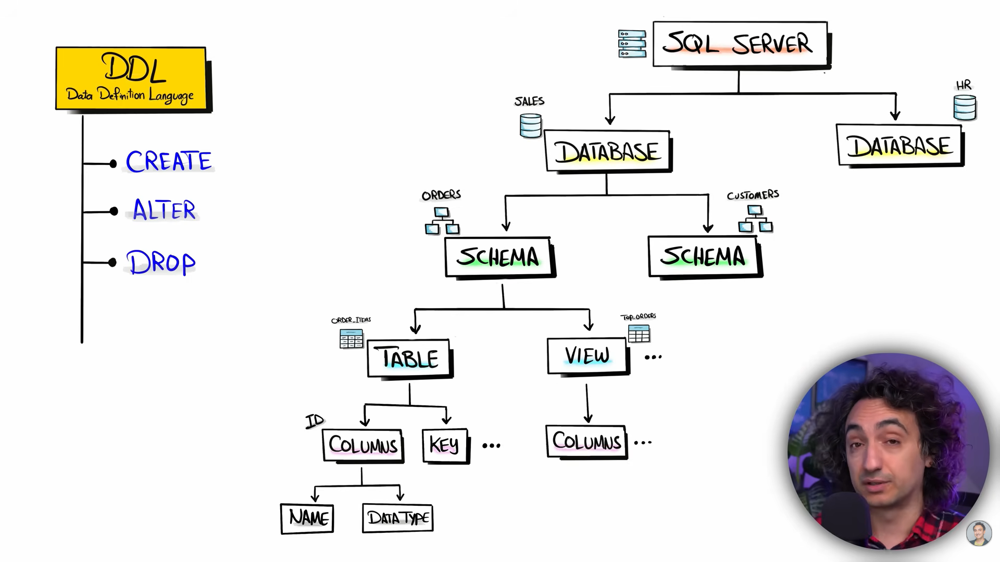

### 3-Levels of Database Architecture :

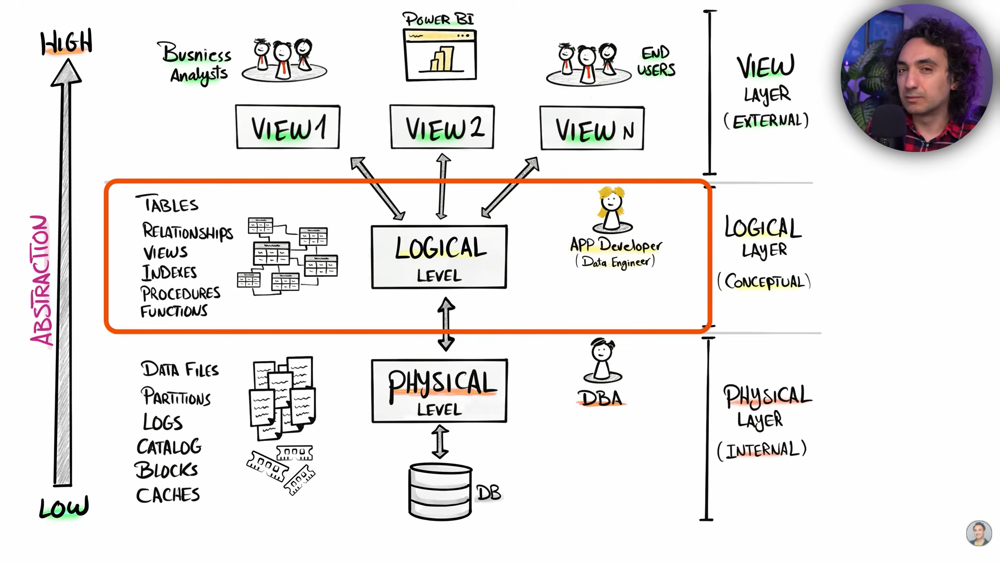

## Intro : 

### DB Table : 

A table is a structured collection of data, similar to a spreadsheet or grid (Excel).

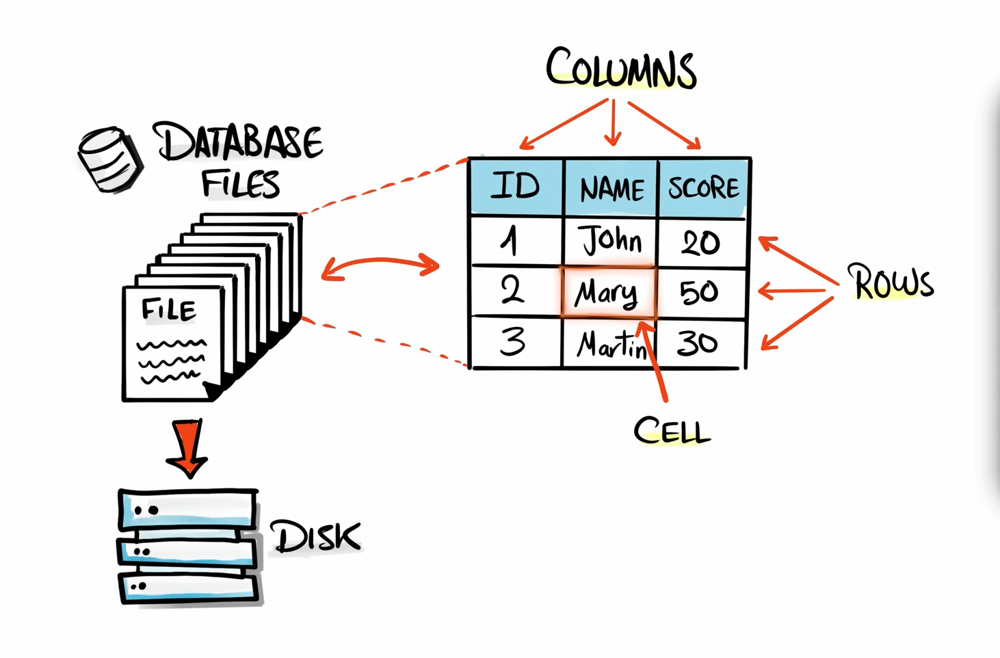

## DB TABLE Types : 

### 1. Permanent Table : 

#### 1. CREATE / INSERT : 

##### Process to create table and data in those table using CREATE / INSERT

1. CREATE : Define the Data Structure of table
2. INSERT : Insert Data into the table

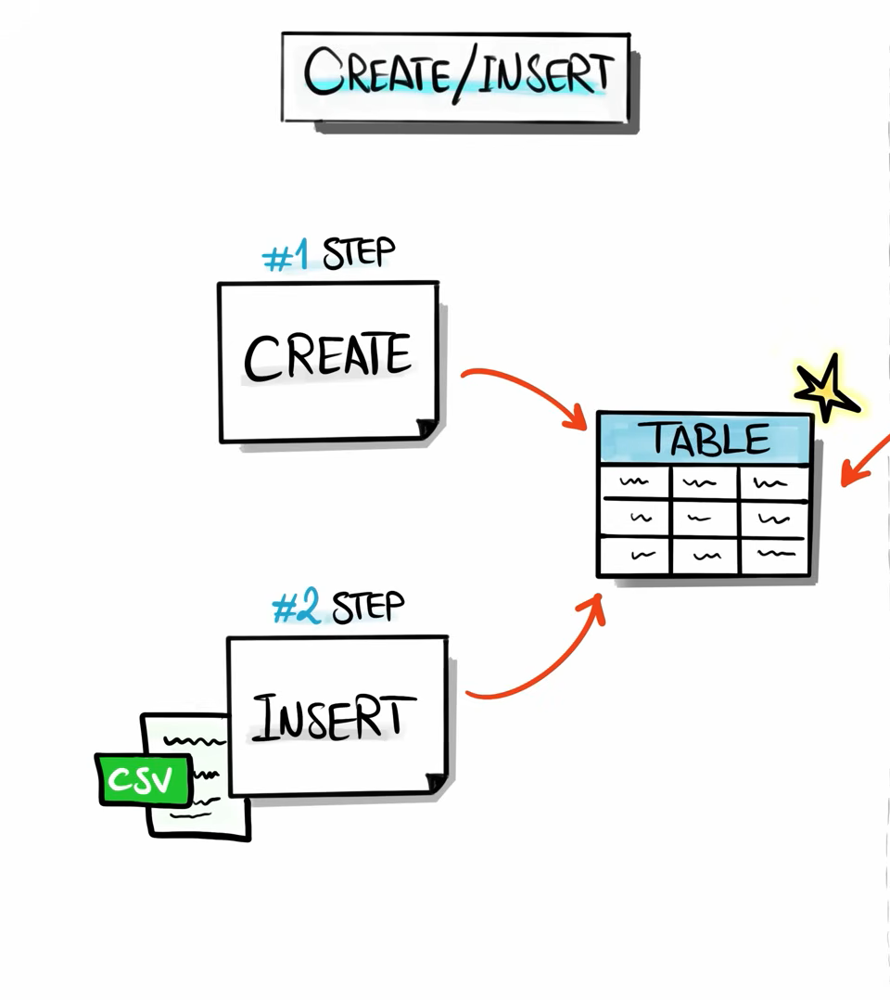

##### CREATE / INSERT Syntax : 

```
-- CREATE : 
CREATE TABLE TableName(
    columnName columnDataType Length,
    columnName columnDataType Length
    -- ID INT,
    -- NAME VARCHAR(50)
)

-- INSERT :
INSERT INTO TableName
VALUES (1, 'Frank')
```

#### 2. CTAS : 

CTAS : Also knwons as --> CREATE TABLE AS SELECT

##### Process to create table using CTAS 

1. Create a new Table based on the result of an SQL Query
2. This brand new table wil be created with data in it

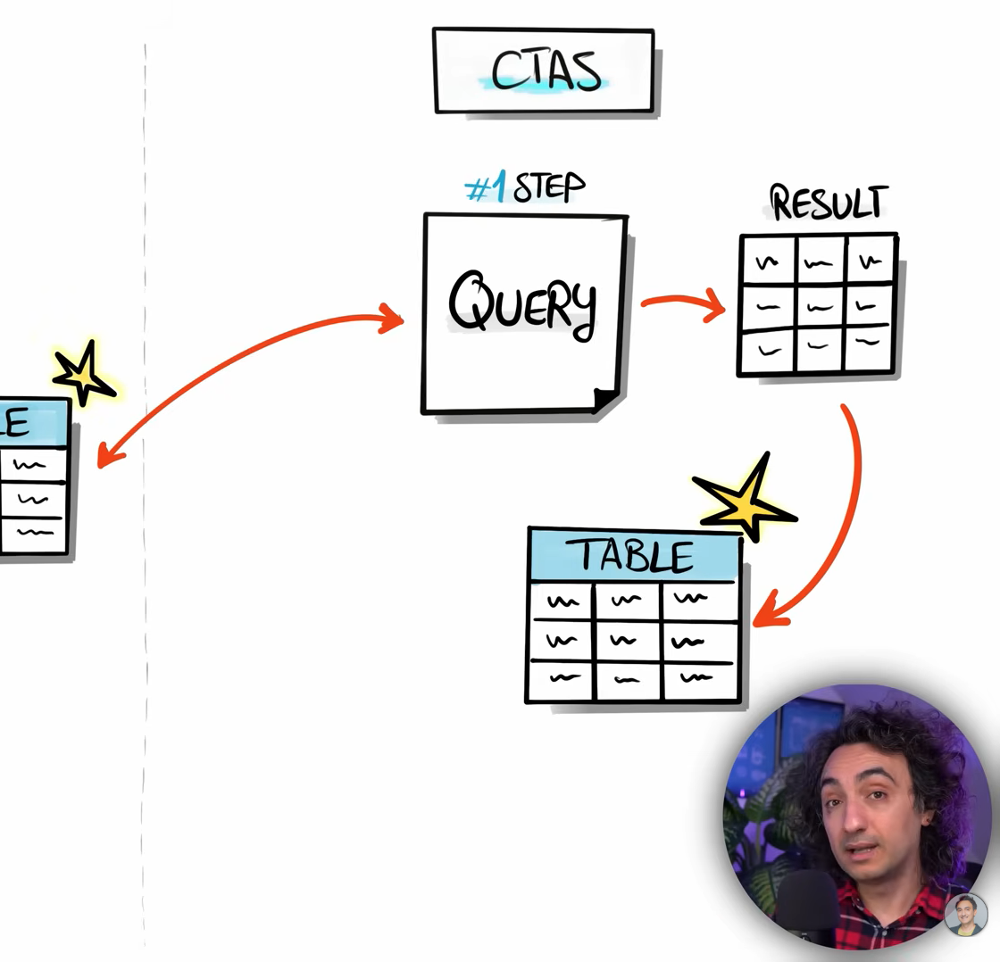

##### CTAS Syntax : 

```
FOR MySQL, Oracle, PostGreSQL :

CREATE TABLE CTAS_TableName AS(
    SELECT ....
    FROM ....
    WHERE ....
)


FOR SQL SERVER :

SELECT ....
INTO CTAS_TableName
FROM ....
WHERE ....
```

#### CTA VS : 

##### 1. CREATE / INSERT vs CTAS : 

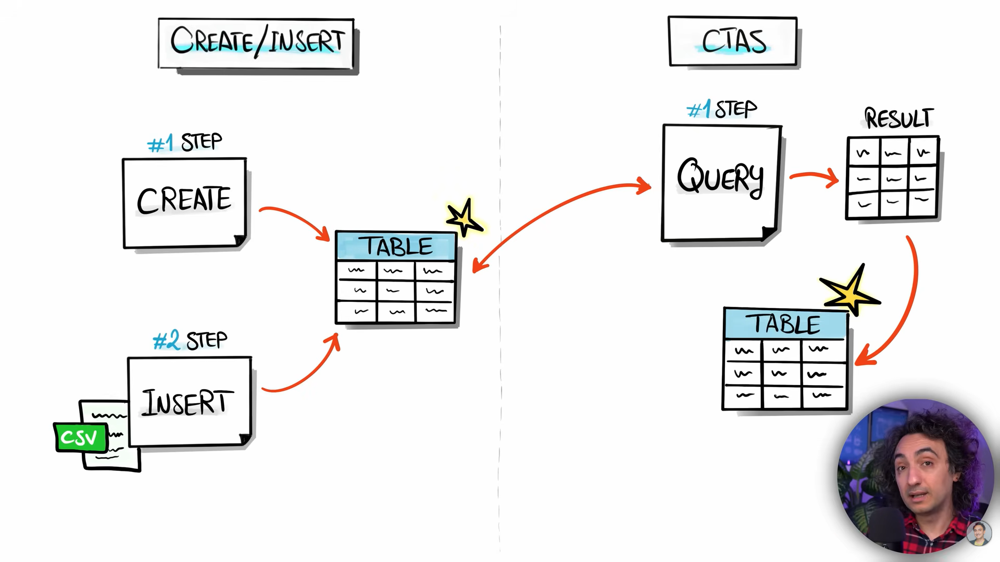

##### 2. CTAS vs VIEWS: 

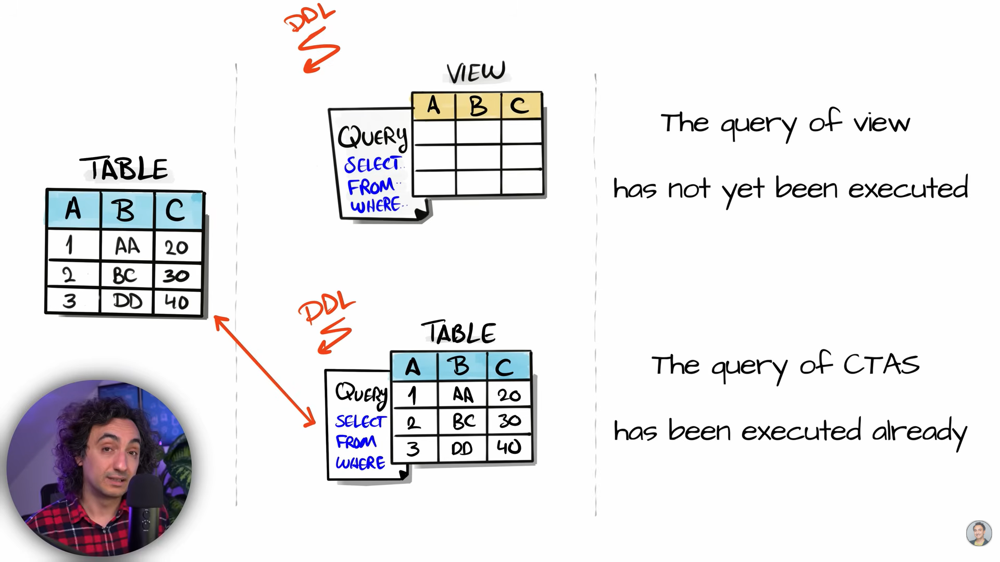

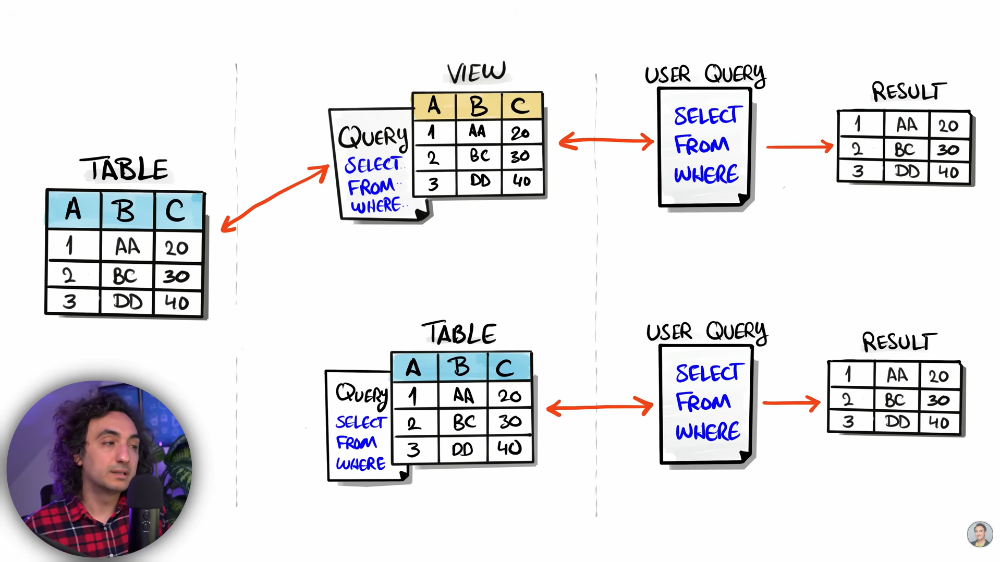

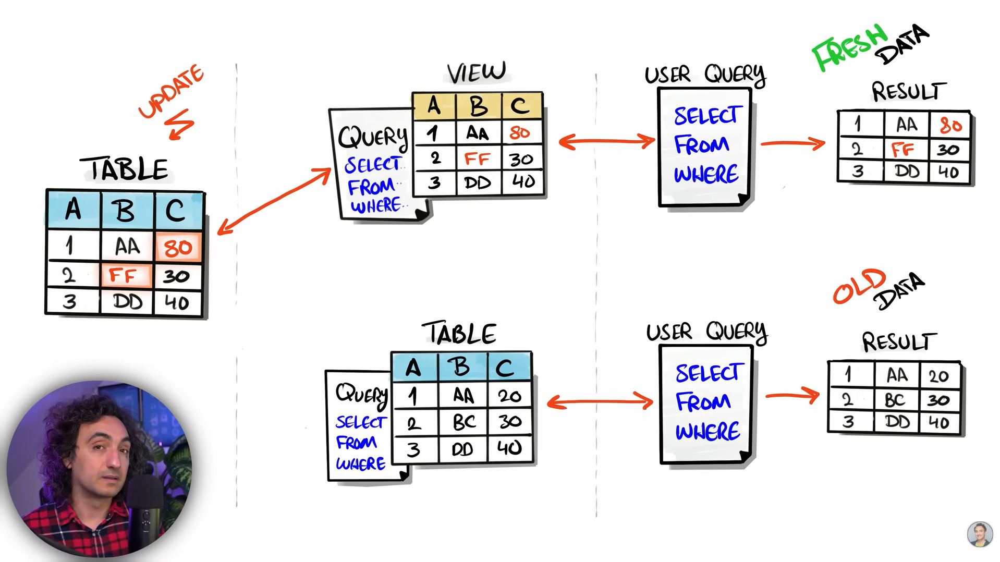

### 2. Temporary Table : 

#### Definition :

Temporary Tables : 
1. Also knows as Temp Table.
2. Stores intermediate results in temporary storage within the database during the session.
3. The database will drop all temporary tables once the session ends.
4. Get stored under Databases --> System Databases --> tempdb --> Temporary Tables

#### Visual : 

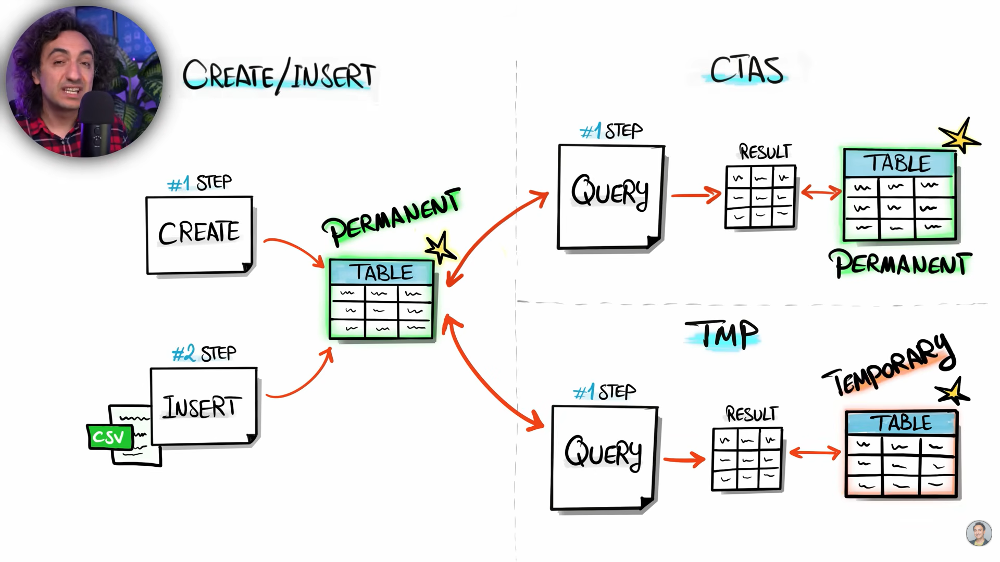

#### Syntax :

```
-- FOR SQL SERVER:
SELECT ....
INTO #NewTempTable
FROM ....
WHERE .... ;

-- FOR MySQL : 
-- USING CTAS : 
CREATE TEMPORARY TABLE TempTableName (ColumnName ColumnType PRIMARY KEY) AS (
    SELECT ....
    FROM ....
    WHERE ....
);
```

#### Challenges :

##### 1. Create a temporary table that contain orderid, order date, orderstatus from order tables.

In [215]:
%%sql
CREATE TEMPORARY TABLE TempOrders (orderid INT PRIMARY KEY) AS(
select orderid, orderdate, orderstatus from orders);

Running query in 'mysql+pymysql://'

10 rows affected.

++
||
++
++

In [216]:
%%sql
select * from TempOrders;

Running query in 'mysql+pymysql://'

10 rows affected.

orderid,orderdate,orderstatus
1,2025-01-01,Delivered
2,2025-01-05,Shipped
3,2025-01-10,Delivered
4,2025-01-20,Shipped
5,2025-02-01,Delivered
6,2025-02-05,Delivered
7,2025-02-15,Delivered
8,2025-02-18,Shipped
9,2025-03-10,Shipped
10,2025-03-15,Shipped


#### How Database EXECUTES TEMP Tables?

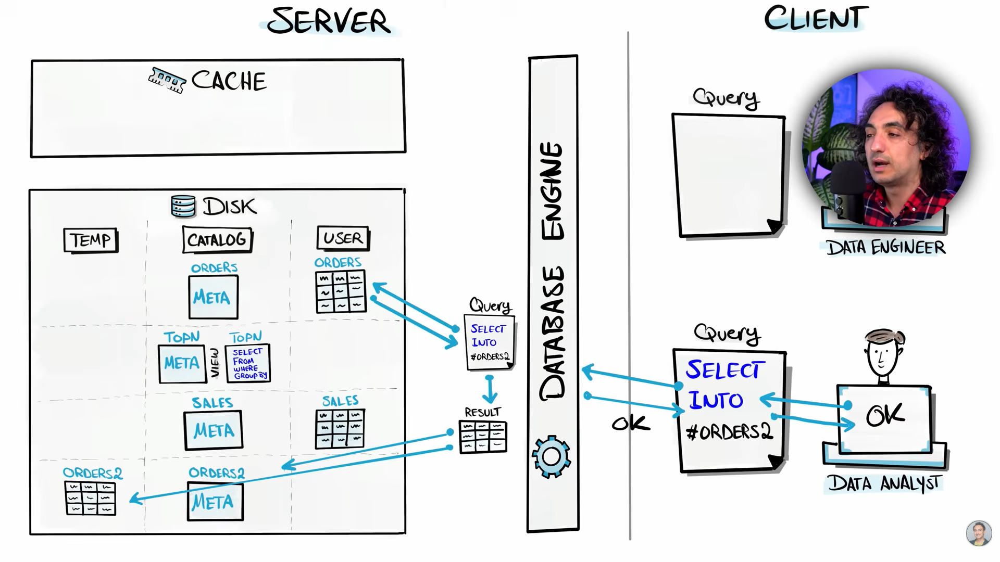

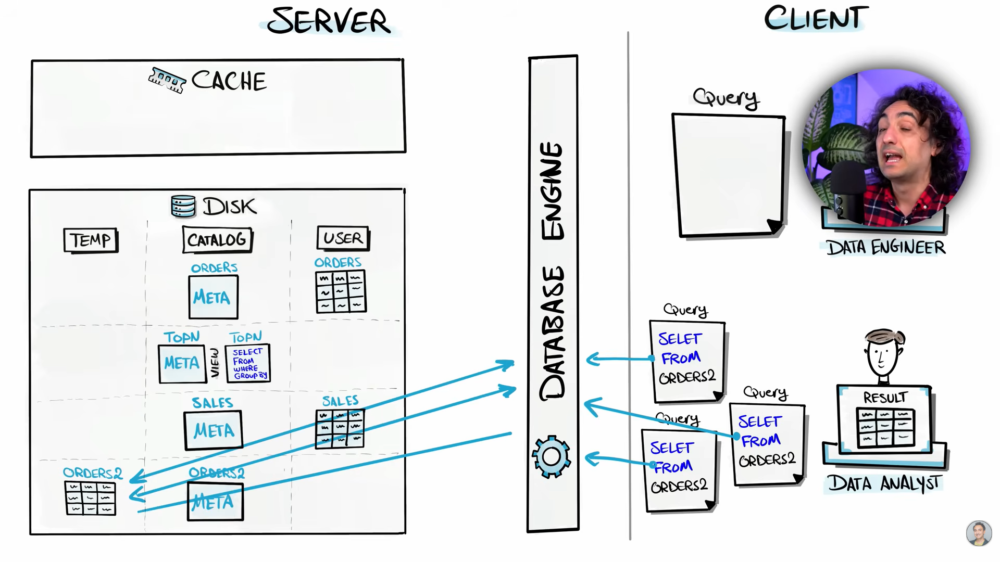

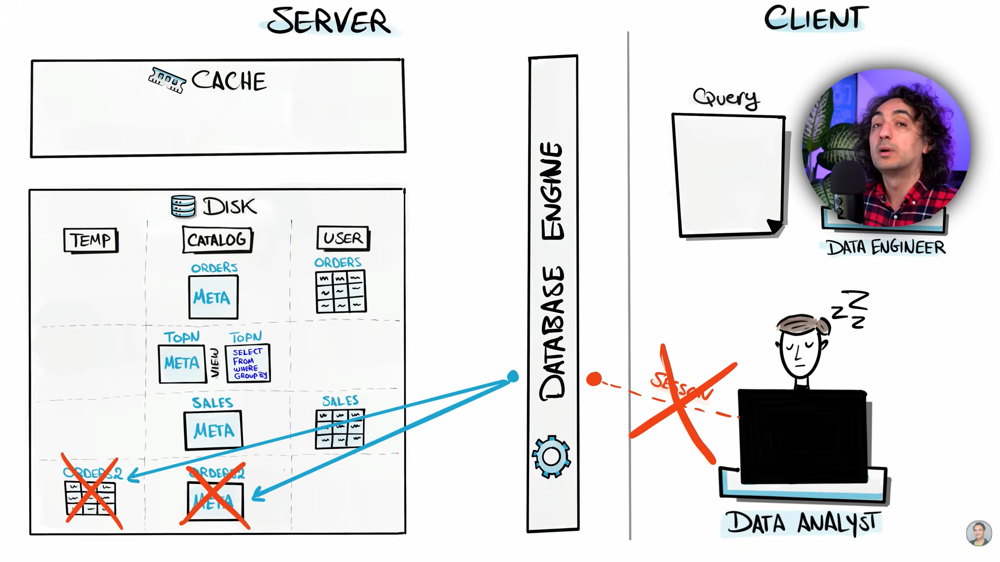

## USECASES : 

### CTAS : 1. Optimize Performance :

#### Visual :

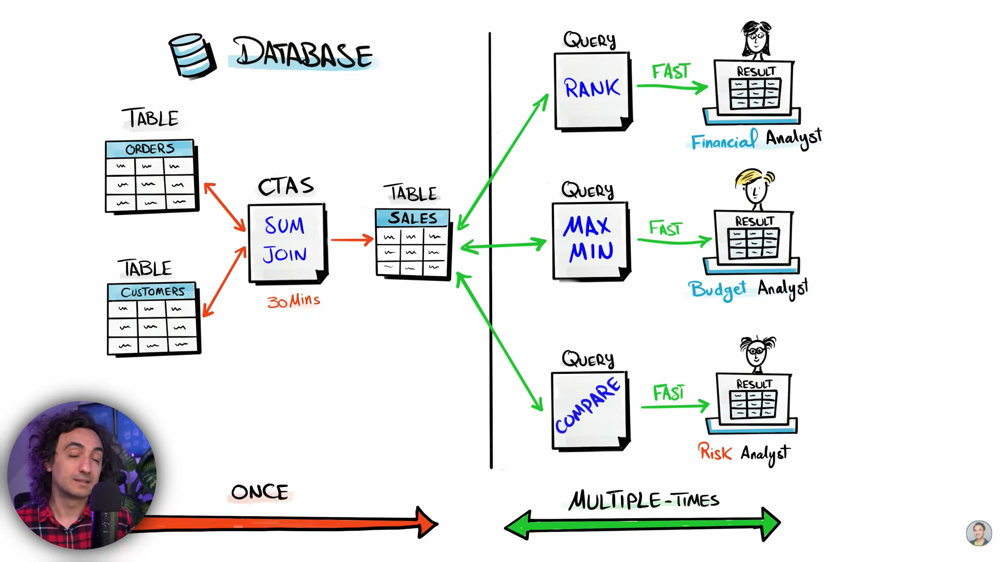

#### Challenges :

##### 1. Create CTAS from Orders and find out month and total sales by month

In [ ]:
%%sql
CREATE TABLE CTAS_Monthly_Sales 
--(RowID INT AUTO_INCREMENT PRIMARY KEY)
(MonthID INT PRIMARY KEY) AS(
    select month(orderdate) as MonthID,
        monthname(orderdate) as Months,
        sum(sales) as TotalSales
    from orders
    group by month(orderdate),
        monthname(orderdate)
);

Running query in 'mysql+pymysql://'

3 rows affected.

++
||
++
++

In [206]:
%%sql
select * from CTAS_Monthly_Sales;

Running query in 'mysql+pymysql://'

3 rows affected.

MonthID,Months,TotalSales
1,January,105
2,February,195
3,March,80


##### 2. How to DROP CTAS Table?

In [197]:
%%sql
DROP TABLE CTAS_Monthly_Sales;

Running query in 'mysql+pymysql://'

++
||
++
++

##### 3. How to update or refresh the CTAS table?

In [208]:
%%sql
DROP TABLE IF EXISTS CTAS_Monthly_Sales;
CREATE TABLE CTAS_Monthly_Sales
(MonthID INT PRIMARY KEY) AS(
    select month(orderdate) as MonthID,
        monthname(orderdate) as Months,
        sum(sales) as TotalSales
    from orders
    group by month(orderdate),
        monthname(orderdate)
);

Running query in 'mysql+pymysql://'

3 rows affected.

++
||
++
++

In [209]:
%%sql
select * from CTAS_Monthly_Sales;

Running query in 'mysql+pymysql://'

3 rows affected.

MonthID,Months,TotalSales
1,January,105
2,February,195
3,March,80


### CTAS : 2. Creating a Snapshot :

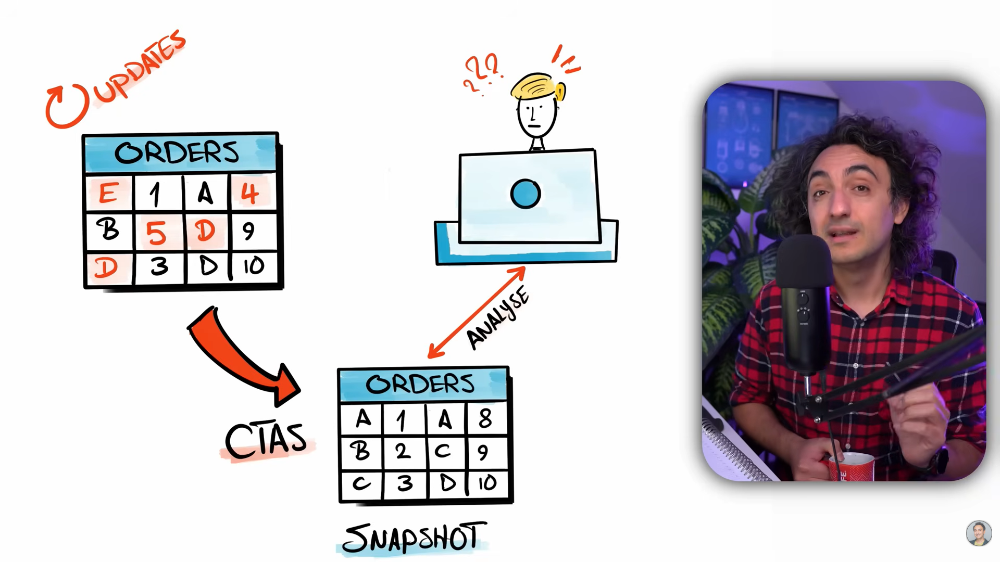

### CTAS : 3. Physical Data Marts in DWH :

Persisting the Data Marts of a DWH improves the speed of data retrieval compared to using VIEWS.

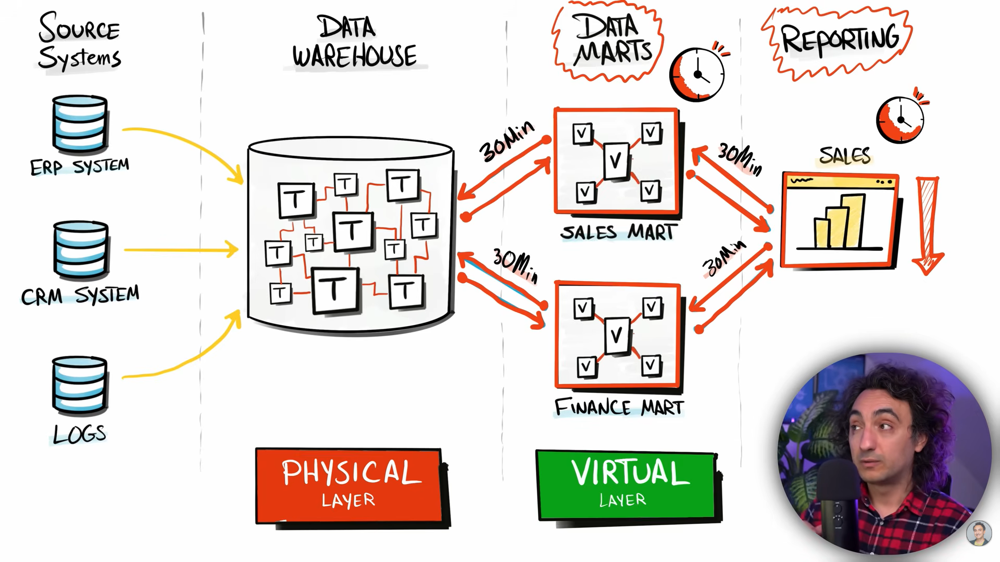

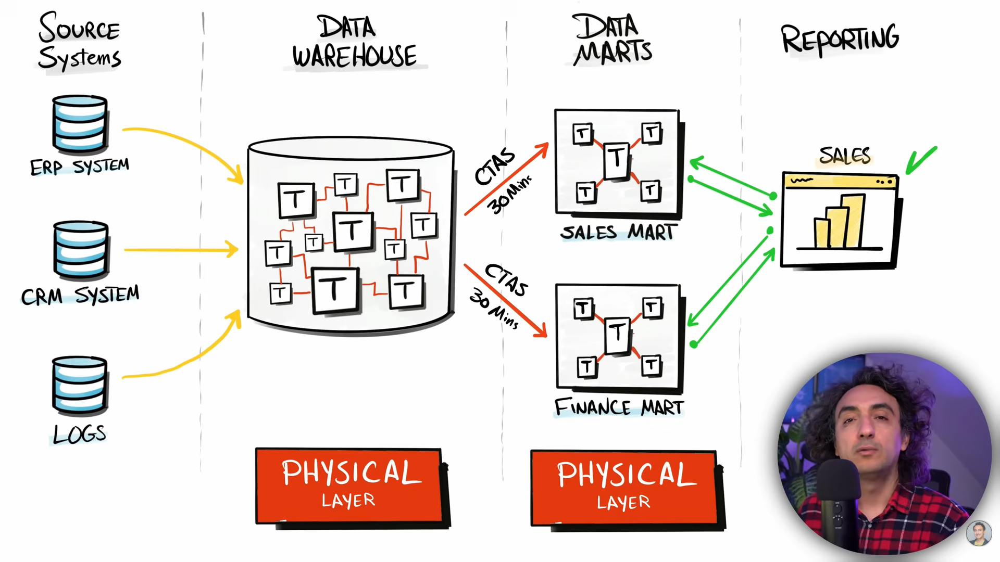

### TEMP : 4. Intermediate Results :

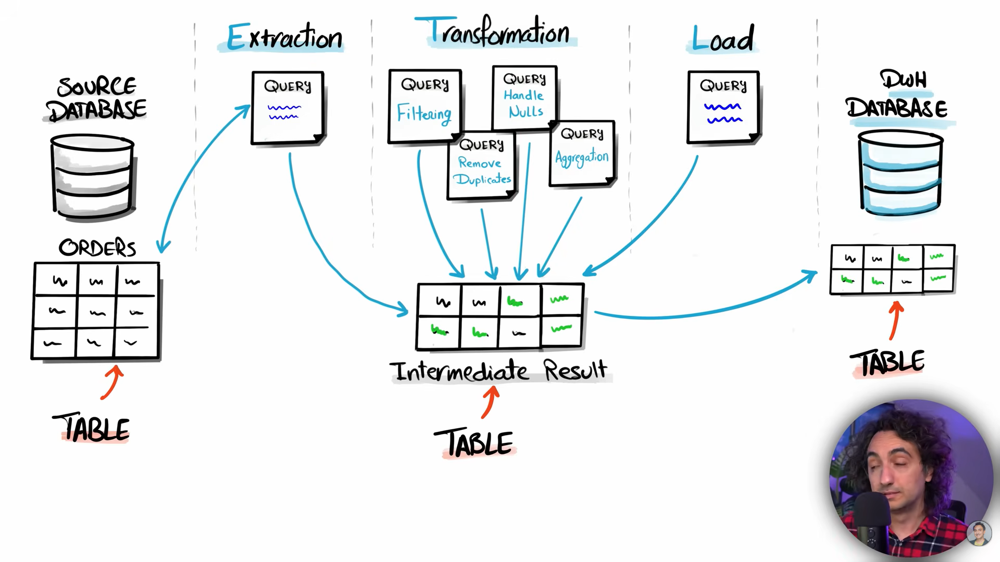

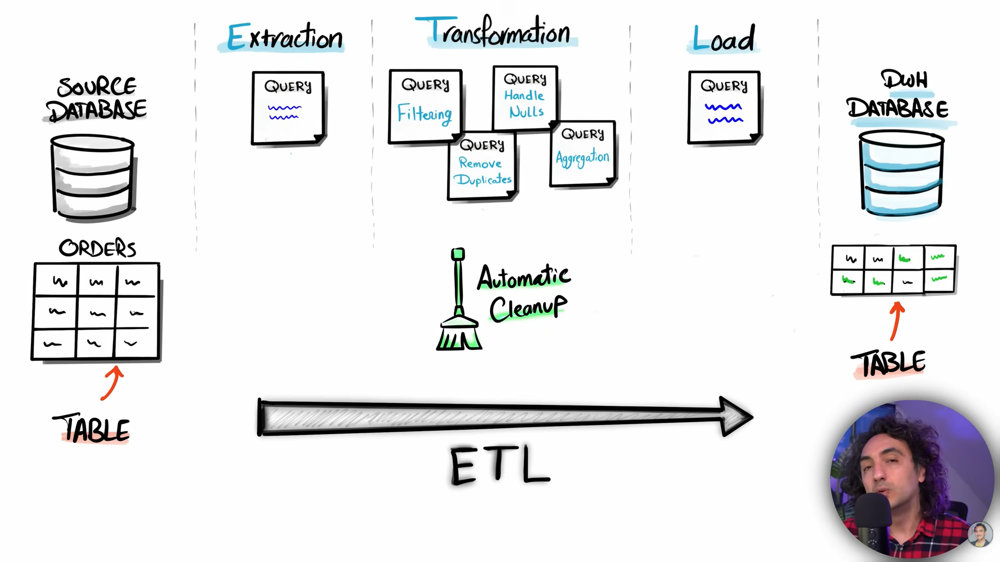

## SUMMARY : 

### SUMMARY : 

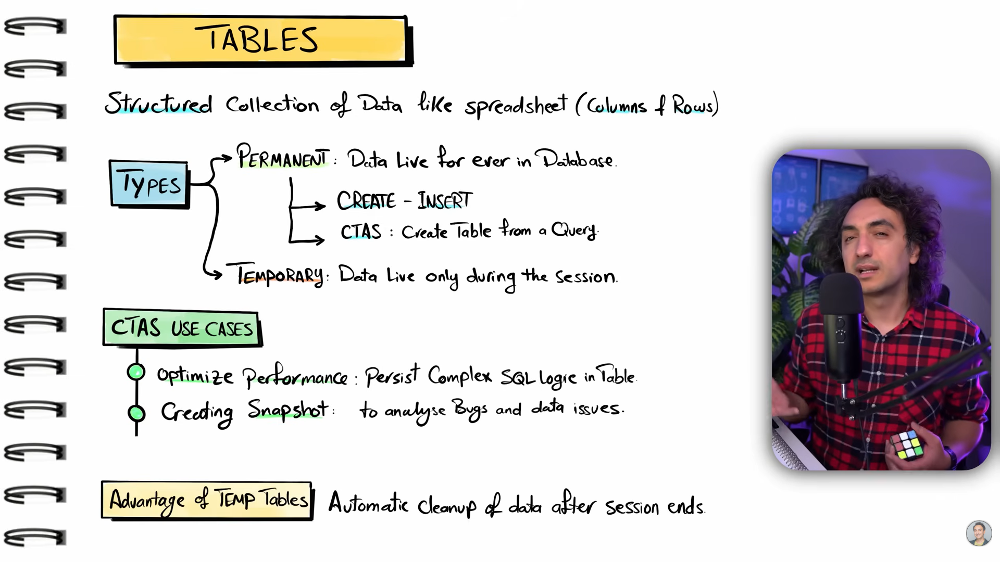

### SubQuery vs CTE vs VIEW vs CTAS vs Temp : 

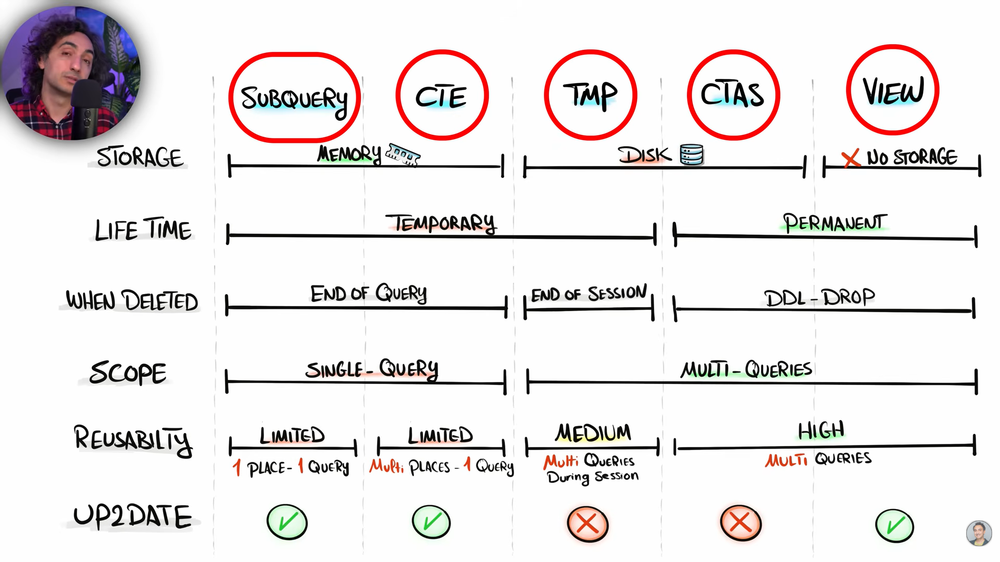

# Extra :

In [2]:
%%sql
use salesdb;

Running query in 'mysql+pymysql://'

++
||
++
++

In [1]:
%%sql
show databases;

Running query in 'mysql+pymysql://'

7 rows affected.

Database
MyDatabase
defaultdb
information_schema
mysql
performance_schema
salesdb
sys
